In [ ]:
%% Homework 2
% due: October 15th, 2026
% Ely Dawson

Starting MATLAB ...


In [ ]:
% First, use your code from last week to load in the multi-year records from the Scripps
% pier. Make sure you’ve made it into a well-commented function and pushed it to the
% Githib repository. If you’re working with a group, it’s fine to push one file per group;
% just let me know which one you were part of.

In [1]:
function [allpier, pierbyyr] = pierdata_allyrs(yr, filepath)
% this function pulls all relevant years of SIO pier data 
% inputs:
%  - yr: years you want to look for. 
%         enter as range or comma seperated list
%      Ex: 2004:2021 or [2004, 2005, 2007]
%  - filepath: specific filepath for finding the pier data
% originally created for SIOC-221a HW1
% updated for use in HW2 Oct 2026
%   - changed code to require input of the years
%       thus allowing for more detailed outputs. 
%   - data only available 2004 - 2023
% Ely J Dawson

    if nargin < 2 || isempty(filepath)
        filepath = pwd;
    end

    n = numel(yr);

    timeAll = cell(n,1);
    tempAll = cell(n,1);
    presAll = cell(n,1);
    dnumAll = cell(n,1);

    pierbyyr = struct();

    for k = 1:n
        filename = fullfile(filepath, ...
            sprintf('scripps_pier-%d.nc', yr(k)));

        time = double(ncread(filename, 'time'));
        temp = double(ncread(filename, 'temperature'));
        pres = double(ncread(filename, 'pressure'));

        % Store this year's data
        data = struct();
        data.time = time(:);
        data.t = temp(:);
        data.p = pres(:);
        data.dnum = datetime(data.time, "ConvertFrom", "posixtime");

        % Sort this year chronologically
        [data.time, idx] = sort(data.time);
        data.t = data.t(idx);
        data.p = data.p(idx);
        data.dnum = data.dnum(idx);

        fieldName = sprintf('yr_%d', yr(k));
        pierbyyr.(fieldName) = data;

        % Collect data for the combined dataset
        timeAll{k} = data.time;
        tempAll{k} = data.t;
        presAll{k} = data.p;
        dnumAll{k} = data.dnum;
    end

    % Combine all requested years
    allpier.time = vertcat(timeAll{:});
    allpier.t = vertcat(tempAll{:});
    allpier.p = vertcat(presAll{:});
    allpier.dnum = vertcat(dnumAll{:});

    [allpier.time, idx] = sort(allpier.time);
    allpier.t = allpier.t(idx);
    allpier.p = allpier.p(idx);
    allpier.dnum = allpier.dnum(idx);
end

[allpier, pierbyyr] = pierdata_allyrs([2016, 2022],'/Users/elydawson/SIO221a_Github_code_2026/data');

Starting MATLAB ...
Executing ...

In [30]:
%% 1: Visual evaluation
% For both temperature and pressure, plot the records from the two years. 

%% Are there obvious discrepancies between the two years? 
% Yes! Starting with temperature, we can see that in 2016 the temperature maxima increased by ~5°C from July to August.
% Compared to 2022, the change was only ~2°C during that same period (22-24°C). 
% We can also see that the temperatures from June to October are vastly different.
% In 2016, the temperatures follow a fairly regular curve. 
% In 2022, we can see that the temperatures are more erratic, and they don't follow an as obvious pattern.
% With pressure, both 2016 and 2022 were comparable. The most obvious discrepancy was with the 2022 graph.
% In April, there was some sort of data error that caused the sensor to give a nonsense reading. 
% The sensor was then mostly likely taken offline for repair for the majority of that month. 

%% What years are covered? Any other observations?
% The two years I chose to cover are 2016 and 2022. I noticed that there is a data gap for 2022 around April. 
% I believe it was due to sensor errors that needed to be repaired. I should look into it further. 

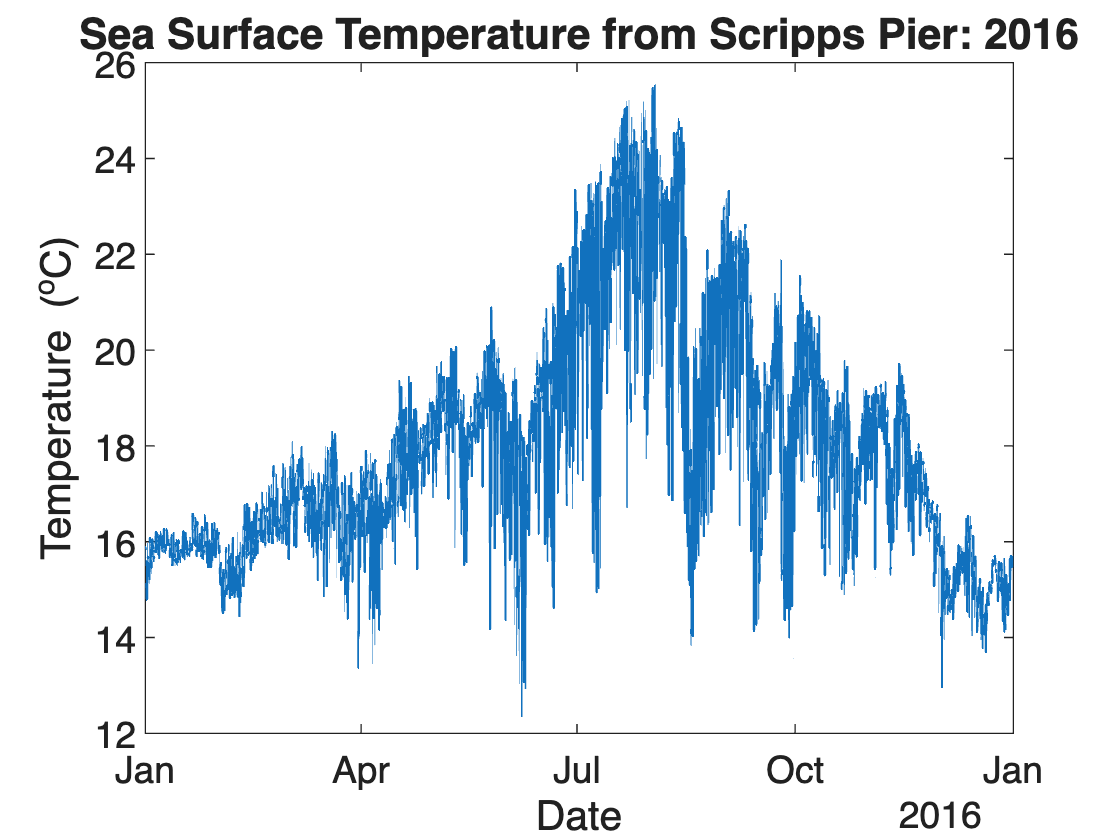

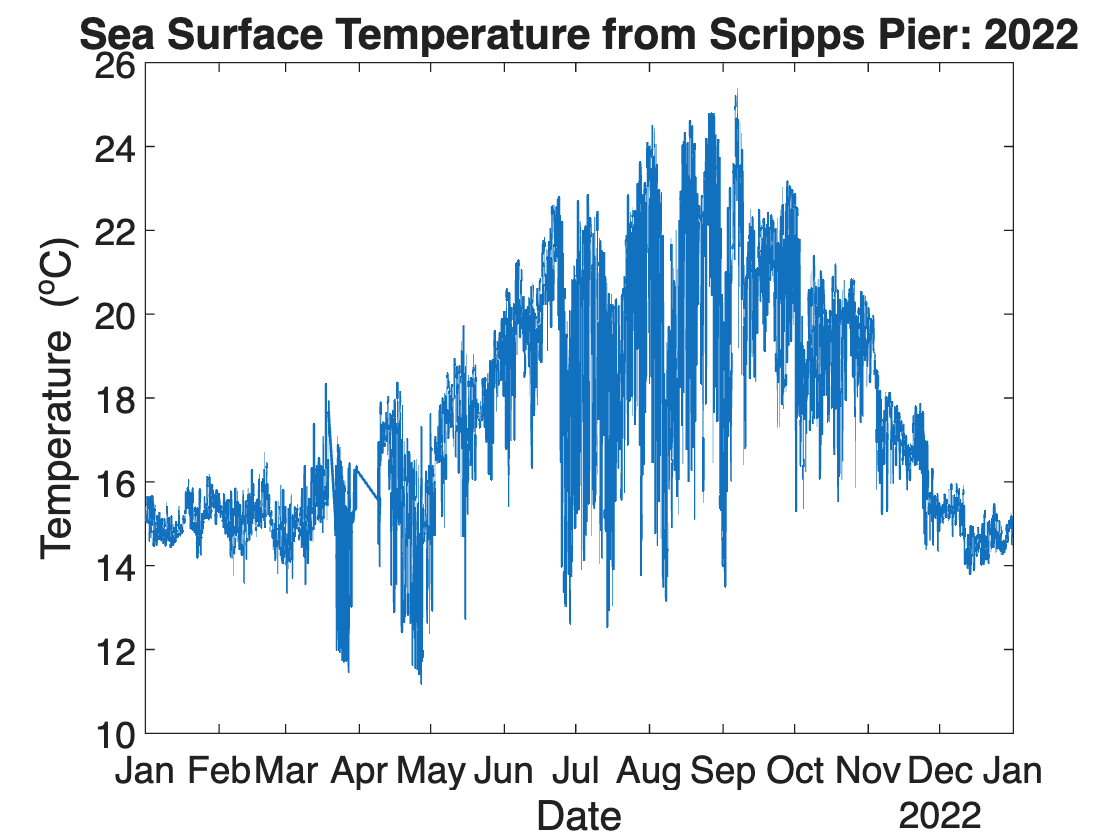

In [2]:
% Temp comparison for 2016 and 2022
figure(1);
plot(pierbyyr.yr_2016.dnum, pierbyyr.yr_2016.t, 'LineWidth', 1)
xtickformat('MMM');
xlabel('Date')
ylabel('Temperature (^oC)')
title('Sea Surface Temperature from Scripps Pier: 2016','fontsize',16)

figure(2); 
plot(pierbyyr.yr_2022.dnum, pierbyyr.yr_2022.t, 'LineWidth', 1)
xtickformat('MMM');
xlabel('Date')
ylabel('Temperature (^oC)')
title('Sea Surface Temperature from Scripps Pier: 2022','fontsize',16)

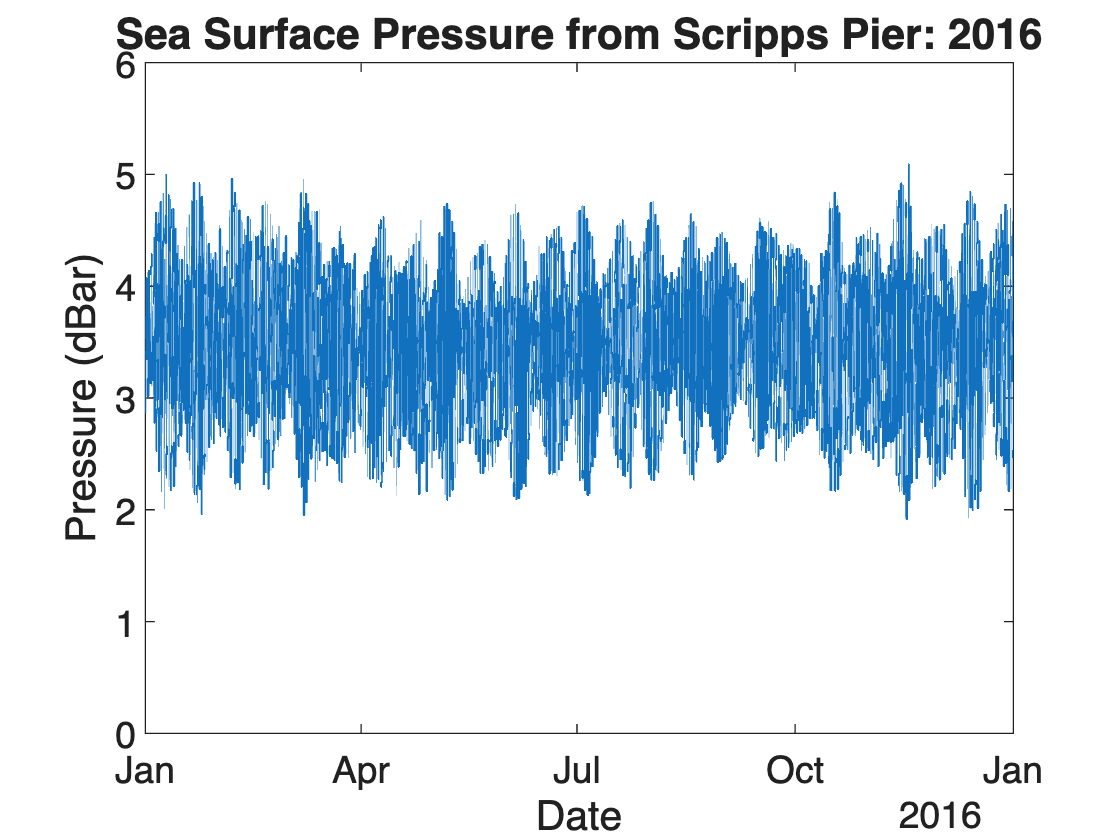

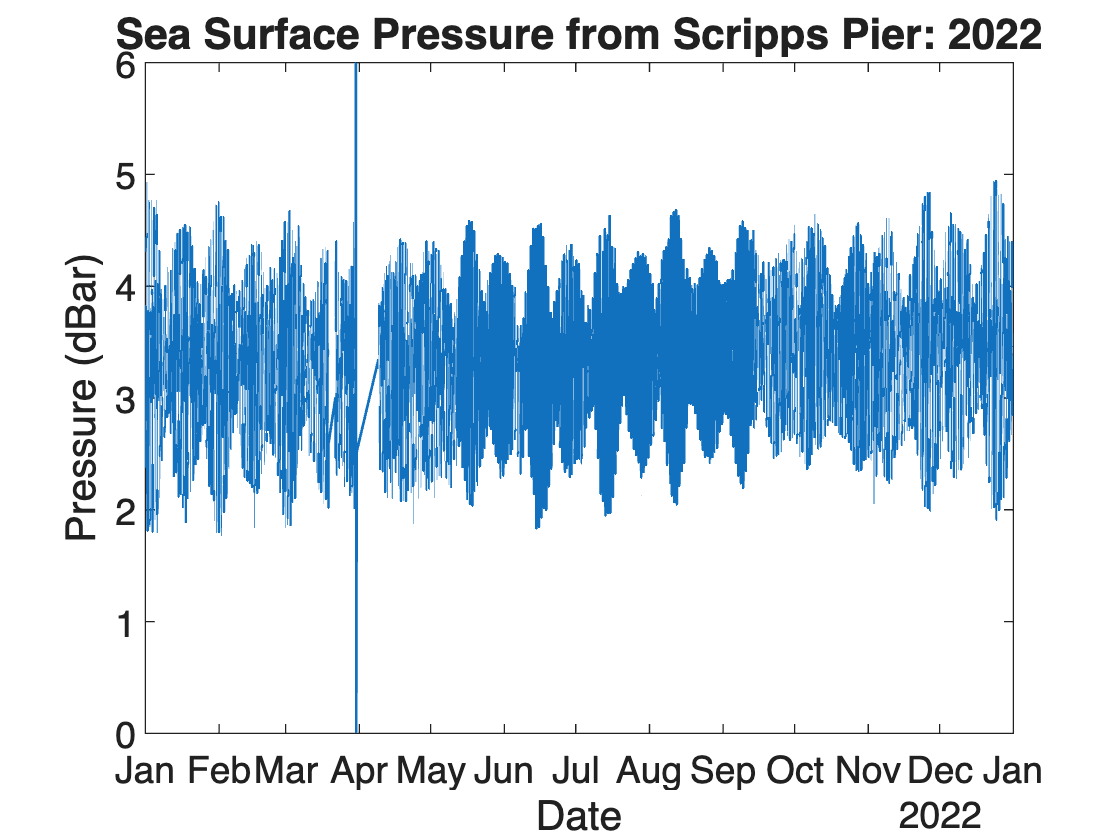

In [3]:
% pressure comparison
figure(3); clf;
plot(pierbyyr.yr_2016.dnum, pierbyyr.yr_2016.p, 'LineWidth', 1)
xtickformat('MMM');
xlabel('Date')
ylabel('Pressure (dBar)')
ylim([0 6])
title('Sea Surface Pressure from Scripps Pier: 2016','fontsize',16)

figure(4); 
plot(pierbyyr.yr_2022.dnum, pierbyyr.yr_2022.p, 'LineWidth', 1)
xtickformat('MMM');
xlabel('Date')
ylabel('Pressure (dBar)')
ylim([0 6])
title('Sea Surface Pressure from Scripps Pier: 2022','fontsize',16)

In [35]:
%% 2: Means.
%% For each quantity, evaluate whether the sample mean between the two years is consistent within error bars.
% Done. Was harder than I expected. I probably overcomplicated it though. 

%% Do you obtain different results if you subsample the data at (say) once per day?
% Yes! As we go from an n=~95,000 data points to just 366 data points, there are far fewer data points to smooth out extrema.
% This can clearly be seen when looking at either temperature or pressure for the two years. 
% The 2016 Mean Pressure: 3.459 +/- 0.0031 when we use all the available data points.
% The 2016 Mean Pressure: 3.305 +/- 0.05 when we use only one data point per day. 
% We can see that our confidence is considerably lower for the single data point per day compared to the full year data.


Temperature
2016 Num: 94466
2016 STD: 2.51
2016 Variance: 6.298
2016 Mean: 18.25 +/- 0.016
2022 Num: 126517
2016 STD: 2.788
2022 Variance: 7.776
2022 Mean: 17.78 +/- 0.015


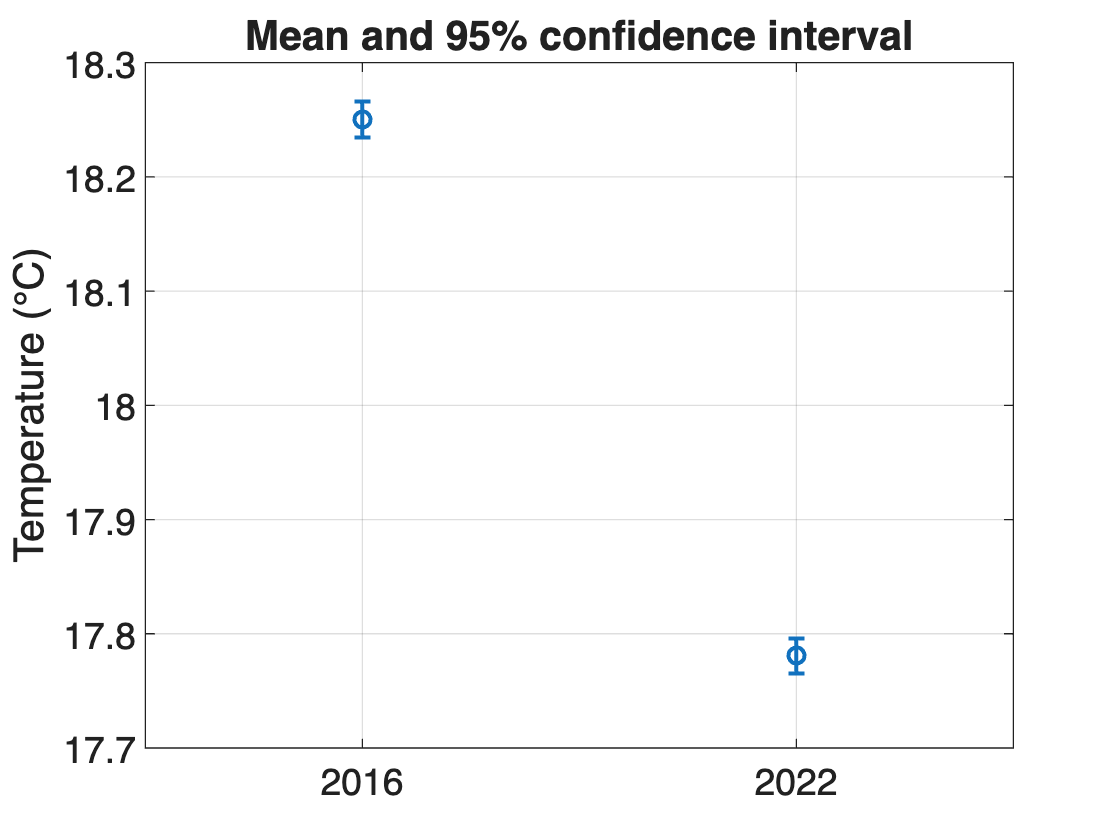


Temperature variance comparison
2016 variance: 6.2978
2022 variance: 7.7757
Variance ratio (2016 / 2022): 0.80993
95% CI for variance ratio: [0.80034, 0.81965]
p-value: 3.3686e-260
Variances differ significantly at the 5% level.


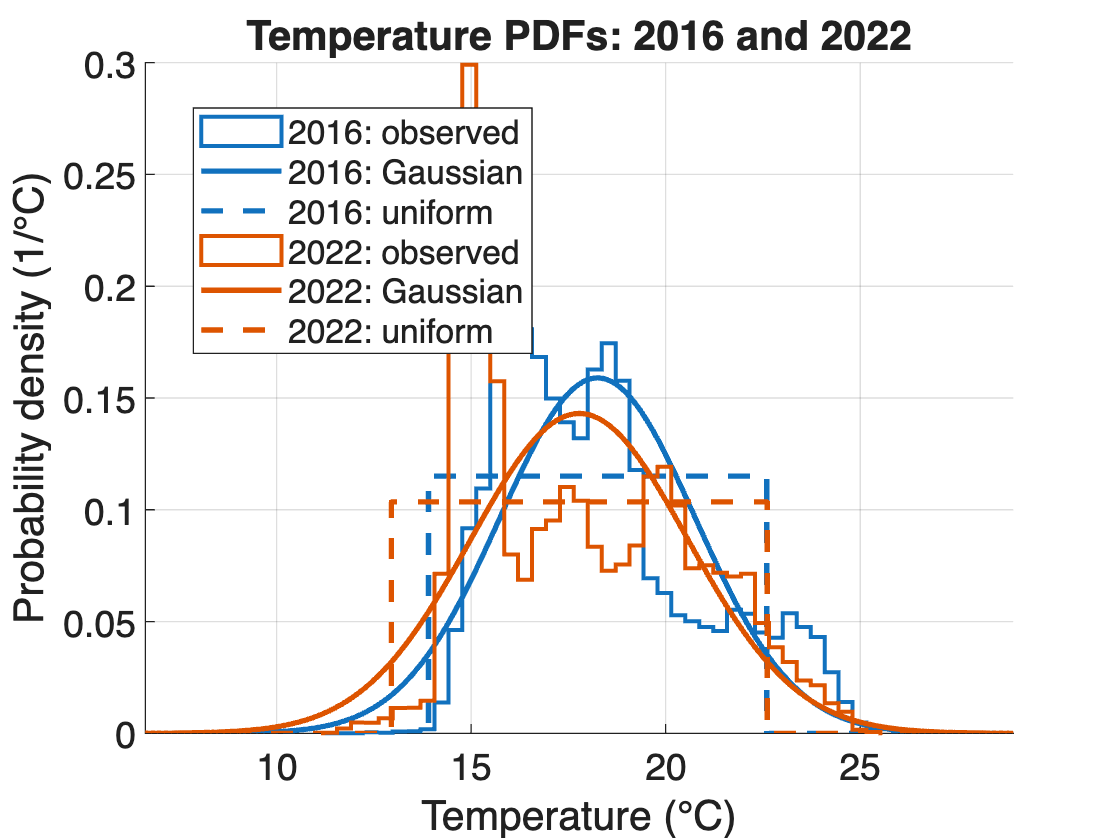


Pressure
2016 Num: 94466
2016 STD: 0.4938
2016 Variance: 0.2438
2016 Mean: 3.459 +/- 0.0031
2022 Num: 126517
2016 STD: 0.5238
2022 Variance: 0.2743
2022 Mean: 3.353 +/- 0.0029


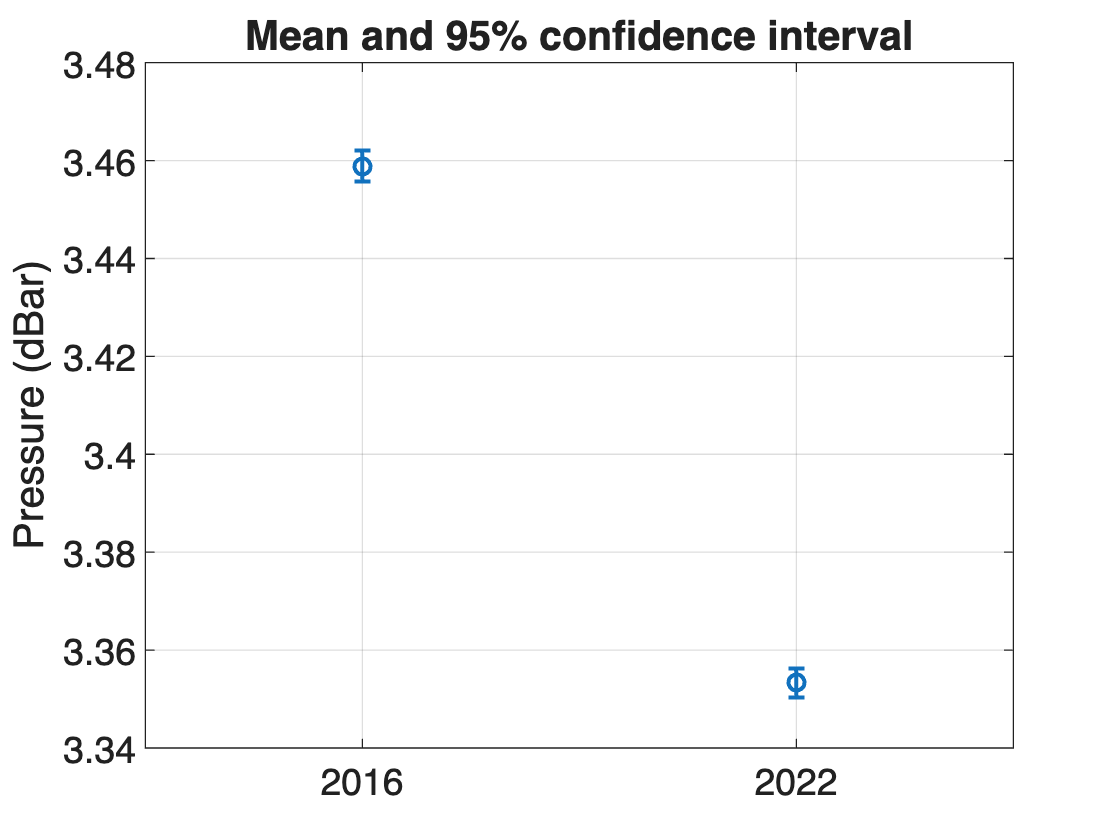


Pressure variance comparison
2016 variance: 0.24383
2022 variance: 0.27432
Variance ratio (2016 / 2022): 0.88884
95% CI for variance ratio: [0.87832, 0.89951]
p-value: 3.9274e-83
Variances differ significantly at the 5% level.


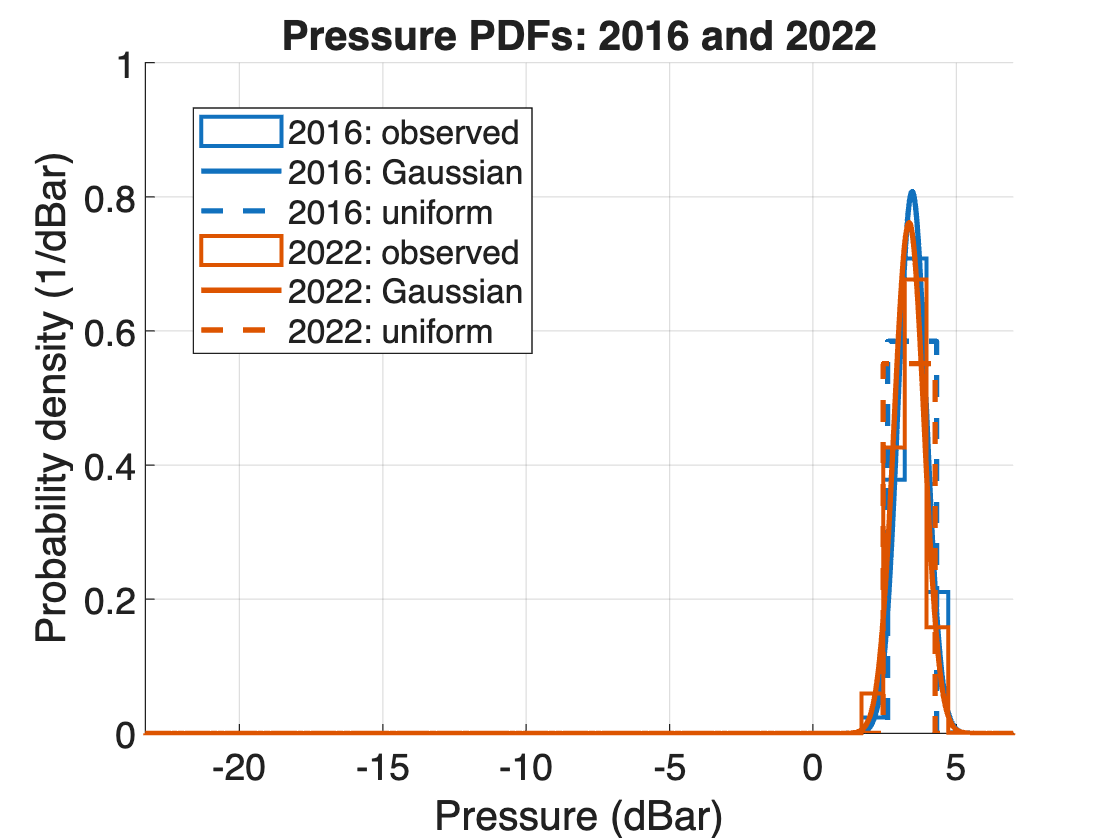

In [30]:
years = [2016, 2022];

vars = {'t', 'p'};
names = {'Temperature', 'Pressure'};
units = {'°C', 'dBar'};

for k = 1:numel(vars)
    data1 = pierbyyr.(sprintf('yr_%d', years(1)));
    data2 = pierbyyr.(sprintf('yr_%d', years(2)));

    x1 = data1.(vars{k});
    x2 = data2.(vars{k});

    x1 = x1(:);
    x2 = x2(:);

    n1 = numel(x1);
    n2 = numel(x2);

    % Means and standard errors
    m1 = mean(x1);
    m2 = mean(x2);

    se1 = std(x1)/sqrt(n1);
    se2 = std(x2)/sqrt(n2);

    % 95% confidence margins for individual means
    margin1 = tinv(0.975, n1-1)*se1;
    margin2 = tinv(0.975, n2-1)*se2;

    fprintf('\n%s\n', names{k});
    fprintf('%d Num: %g\n', years(1), n1);
    fprintf('%d STD: %.4g\n', years(1), std(x1));
    fprintf('%d Variance: %.4g\n', years(1), std(x1)^2);
    fprintf('%d Mean: %.4g +/- %.2g\n', years(1), m1, margin1);
    
    fprintf('%d Num: %g\n', years(2), n2);
    fprintf('%d STD: %.4g\n', years(1), std(x2));
    fprintf('%d Variance: %.4g\n', years(2), std(x2)^2);
    fprintf('%d Mean: %.4g +/- %.2g\n', years(2), m2, margin2);

    figure;
    errorbar([1 2], [m1 m2], [margin1 margin2], 'o', 'LineWidth', 1.5);
    set(gca, 'XTick', [1 2], 'XTickLabel', {num2str(years(1)), num2str(years(2))});
    ylabel(sprintf('%s (%s)', names{k}, units{k}));
    xlim([0.5 2.5]);
    title('Mean and 95% confidence interval');
    grid on;
    drawnow;
    
    alpha = 0.05;

    [hVar, pVar, varianceRatioCI] = vartest2(x1, x2, 'Alpha', alpha);

    v1 = var(x1);
    v2 = var(x2);
    varianceRatio = v1/v2;

    fprintf('\n%s variance comparison\n', names{k});
    fprintf('%d variance: %.5g\n', years(1), v1);
    fprintf('%d variance: %.5g\n', years(2), v2);
    fprintf('Variance ratio (%d / %d): %.5g\n', ...
    years(1), years(2), varianceRatio);
    fprintf('95%% CI for variance ratio: [%.5g, %.5g]\n', ...
    varianceRatioCI(1), varianceRatioCI(2));
    fprintf('p-value: %.5g\n', pVar);

    if hVar == 0
        fprintf('No significant difference in variance at the 5%% level.\n');
    else
        fprintf('Variances differ significantly at the 5%% level.\n');
    end


    samples = {x1, x2};
    means = [m1, m2];
    sigmas = [std(x1), std(x2)];
    colors = lines(2);

    assert(all(sigmas > 0), ...
        'Both years must have nonzero variance to plot these PDFs.');

    % Use the same histogram bins for both years
    combined = [x1; x2];
    edges = linspace(min(combined), max(combined), 41);

    % Plot range includes the data and fitted distributions
    xmin = min([min(combined), means - 4*sigmas]);
    xmax = max([max(combined), means + 4*sigmas]);
    xgrid = linspace(xmin, xmax, 1000);

    figure;
    hold on;

    for j = 1:numel(years)
        mu = means(j);
        sigma = sigmas(j);
        c = colors(j,:);

        histogram(samples{j}, edges, ...
            'Normalization', 'pdf', ...
            'DisplayStyle', 'stairs', ...
            'EdgeColor', c, 'LineWidth', 1.5, ...
            'DisplayName', sprintf('%d: observed', years(j)));

        gaussianPDF = exp(-0.5*((xgrid-mu)/sigma).^2) ...
            / (sigma*sqrt(2*pi));

        plot(xgrid, gaussianPDF, '-', ...
            'Color', c, 'LineWidth', 2, ...
            'DisplayName', sprintf('%d: Gaussian', years(j)));
            
        a = mu - sqrt(3)*sigma;
        b = mu + sqrt(3)*sigma;
        height = 1/(b-a);

        plot([xmin a a b b xmax], [0 0 height height 0 0], '--', ...
            'Color', c, 'LineWidth', 2, ...
            'DisplayName', sprintf('%d: uniform', years(j)));
    end

    xlabel(sprintf('%s (%s)', names{k}, units{k}));
    ylabel(sprintf('Probability density (1/%s)', units{k}));
    title(sprintf('%s PDFs: %d and %d', ...
        names{k}, years(1), years(2)));
    legend('Location', 'best');
    xlim([xmin xmax]);
    grid on;
    hold off;
end


Temperature — one reading per day
2016 Num: 366
2016 STD: 2.558
2016 Variance: 6.545
2016 Mean: 18.62 +/- 0.26
2022 Num: 356
2022 STD: 2.851
2022 Variance: 8.129
2022 Mean: 18.23 +/- 0.3


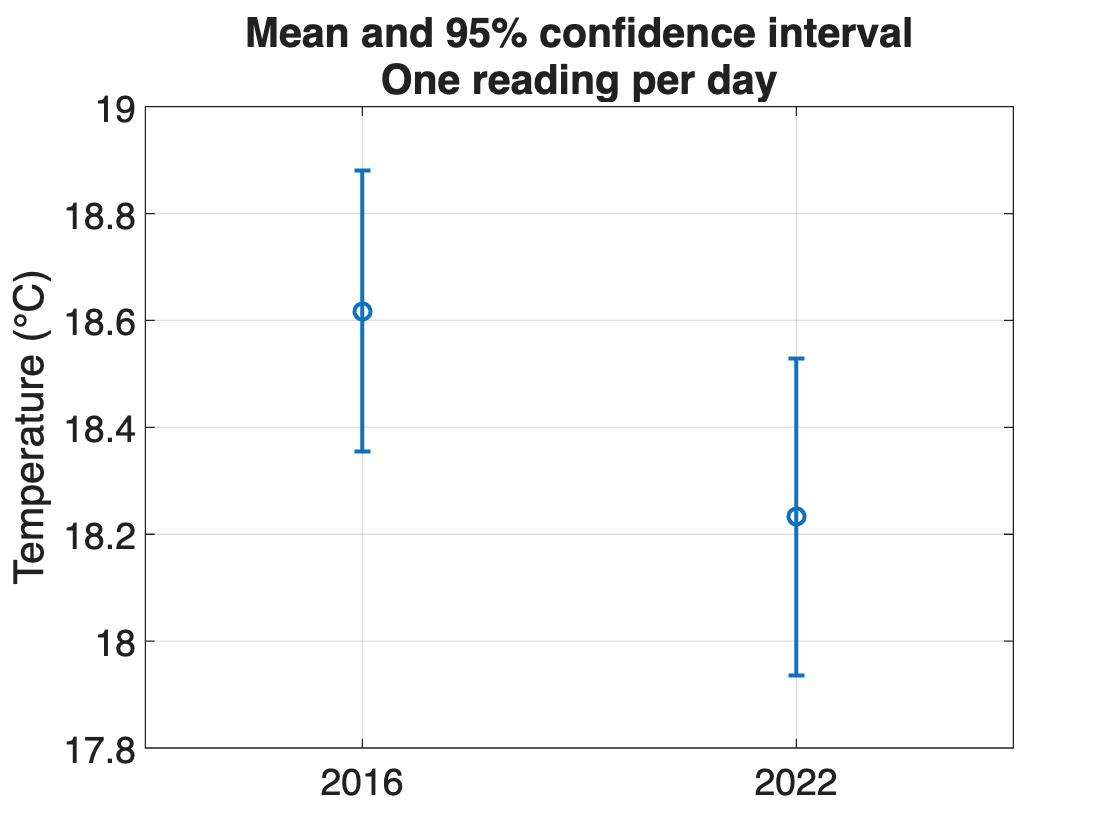


Temperature variance comparison
2016 variance: 6.545
2022 variance: 8.1289
Variance ratio (2016 / 2022): 0.80515
95% CI for variance ratio: [0.65454, 0.99012]
p-value: 0.039985
Variances differ significantly at the 5% level.


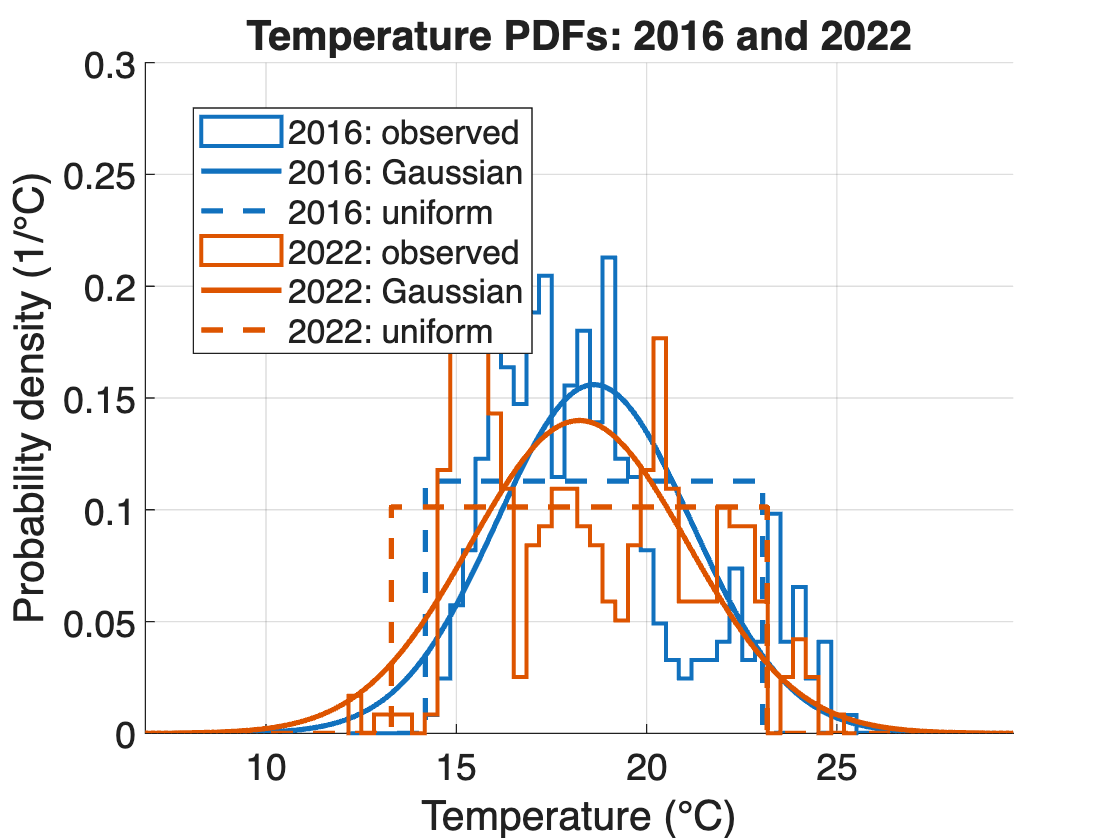


Pressure — one reading per day
2016 Num: 366
2016 STD: 0.4845
2016 Variance: 0.2347
2016 Mean: 3.305 +/- 0.05
2022 Num: 356
2022 STD: 0.5083
2022 Variance: 0.2584
2022 Mean: 3.201 +/- 0.053


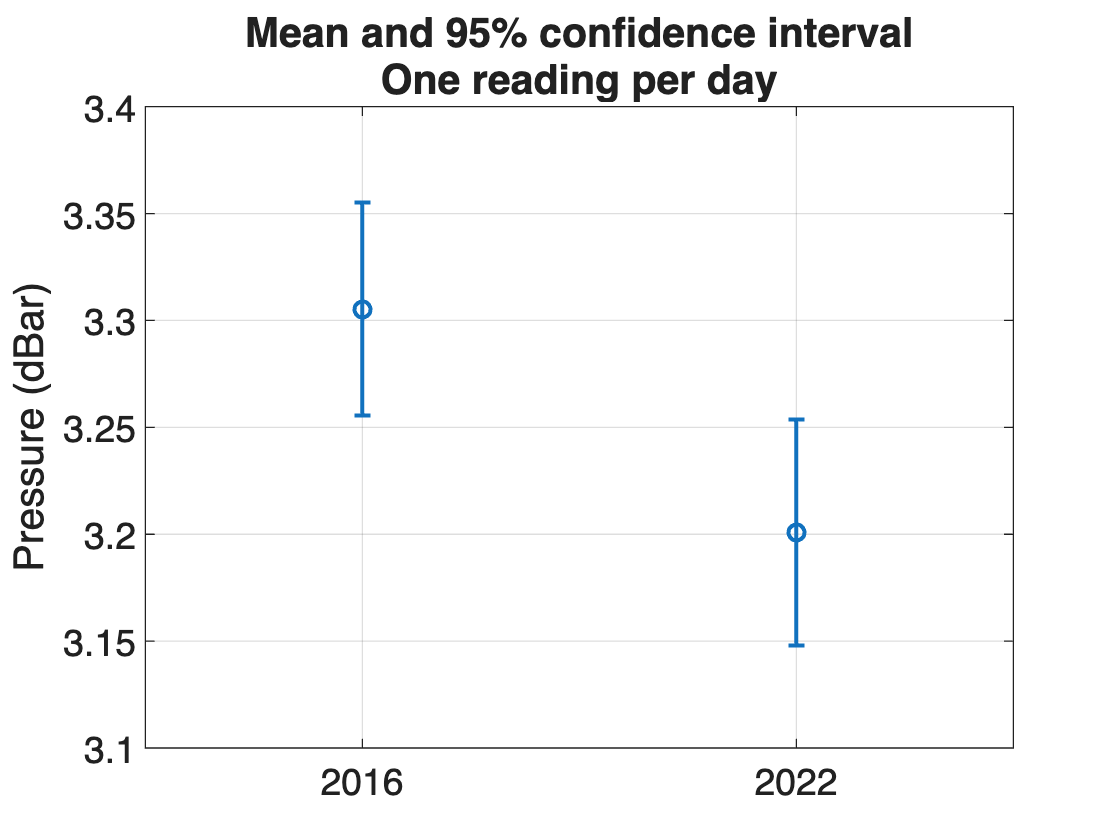


Pressure variance comparison
2016 variance: 0.23472
2022 variance: 0.25838
Variance ratio (2016 / 2022): 0.90842
95% CI for variance ratio: [0.73849, 1.1171]
p-value: 0.36231
No significant difference in variance at the 5% level.


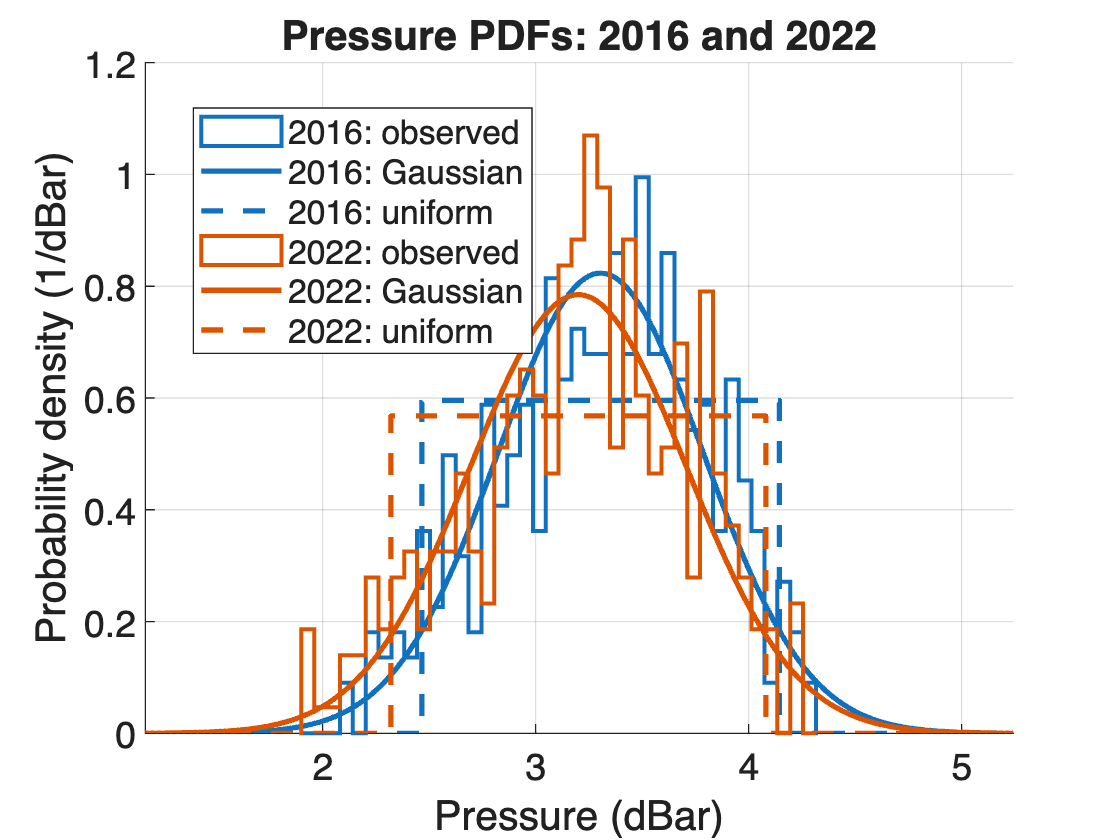

In [29]:
years = [2016, 2022];

vars = {'t', 'p'};
names = {'Temperature', 'Pressure'};
units = {'°C', 'dBar'};

data1 = pierbyyr.(sprintf('yr_%d', years(1)));
data2 = pierbyyr.(sprintf('yr_%d', years(2)));

% Sort timestamps and exclude missing dates
[time1, order1] = sort(data1.dnum(:));
[time2, order2] = sort(data2.dnum(:));

valid1 = ~isnat(time1);
valid2 = ~isnat(time2);

time1 = time1(valid1);
order1 = order1(valid1);
time2 = time2(valid2);
order2 = order2(valid2);

% Find the first chronological reading of each day
[~, daily1] = unique(dateshift(time1, 'start', 'day'), 'stable');
[~, daily2] = unique(dateshift(time2, 'start', 'day'), 'stable');

idx1 = order1(daily1);
idx2 = order2(daily2);

for k = 1:numel(vars)
    x1 = data1.(vars{k});
    x2 = data2.(vars{k});

    % Subsample: one reading per day
    x1 = x1(idx1);
    x2 = x2(idx2);

    % Make column vectors and remove invalid readings
    x1 = x1(:);
    x2 = x2(:);

    n1 = numel(x1);
    n2 = numel(x2);

    % Means and standard errors
    m1 = mean(x1);
    m2 = mean(x2);

    se1 = std(x1)/sqrt(n1);
    se2 = std(x2)/sqrt(n2);

    % 95% confidence margins for individual means
    margin1 = tinv(0.975, n1-1)*se1;
    margin2 = tinv(0.975, n2-1)*se2;

    fprintf('\n%s — one reading per day\n', names{k});
    fprintf('%d Num: %g\n', years(1), n1);
    fprintf('%d STD: %.4g\n', years(1), std(x1));
    fprintf('%d Variance: %.4g\n', years(1), std(x1)^2);
    fprintf('%d Mean: %.4g +/- %.2g\n', years(1), m1, margin1);

    fprintf('%d Num: %g\n', years(2), n2);
    fprintf('%d STD: %.4g\n', years(2), std(x2));
    fprintf('%d Variance: %.4g\n', years(2), std(x2)^2);
    fprintf('%d Mean: %.4g +/- %.2g\n', years(2), m2, margin2);

    figure;
    errorbar([1 2], [m1 m2], [margin1 margin2], 'o', ...
        'LineWidth', 1.5);
    set(gca, 'XTick', [1 2], ...
        'XTickLabel', {num2str(years(1)), num2str(years(2))});
    ylabel(sprintf('%s (%s)', names{k}, units{k}));
    xlim([0.5 2.5]);
    title({'Mean and 95% confidence interval', ...
        'One reading per day'});
    grid on;
    drawnow;

    alpha = 0.05;

    [hVar, pVar, varianceRatioCI] = vartest2(x1, x2, 'Alpha', alpha);

    v1 = var(x1);
    v2 = var(x2);
    varianceRatio = v1/v2;

    fprintf('\n%s variance comparison\n', names{k});
    fprintf('%d variance: %.5g\n', years(1), v1);
    fprintf('%d variance: %.5g\n', years(2), v2);
    fprintf('Variance ratio (%d / %d): %.5g\n', ...
    years(1), years(2), varianceRatio);
    fprintf('95%% CI for variance ratio: [%.5g, %.5g]\n', ...
    varianceRatioCI(1), varianceRatioCI(2));
    fprintf('p-value: %.5g\n', pVar);

    if hVar == 0
        fprintf('No significant difference in variance at the 5%% level.\n');
    else
        fprintf('Variances differ significantly at the 5%% level.\n');
    end

    samples = {x1, x2};
    means = [m1, m2];
    sigmas = [std(x1), std(x2)];
    colors = lines(2);

    combined = [x1; x2];
    edges = linspace(min(combined), max(combined), 41);

    xmin = min([min(combined), means - 4*sigmas]);
    xmax = max([max(combined), means + 4*sigmas]);
    xgrid = linspace(xmin, xmax, 1000);

    figure;
    hold on;

    for j = 1:numel(years)
        mu = means(j);
        sigma = sigmas(j);
        c = colors(j,:);

        histogram(samples{j}, edges, ...
            'Normalization', 'pdf', ...
            'DisplayStyle', 'stairs', ...
            'EdgeColor', c, 'LineWidth', 1.5, ...
            'DisplayName', sprintf('%d: observed', years(j)));

        gaussianPDF = exp(-0.5*((xgrid-mu)/sigma).^2) ...
            / (sigma*sqrt(2*pi));

        plot(xgrid, gaussianPDF, '-', ...
            'Color', c, 'LineWidth', 2, ...
            'DisplayName', sprintf('%d: Gaussian', years(j)));

        a = mu - sqrt(3)*sigma;
        b = mu + sqrt(3)*sigma;
        height = 1/(b-a);

        plot([xmin a a b b xmax], [0 0 height height 0 0], '--', ...
            'Color', c, 'LineWidth', 2, ...
            'DisplayName', sprintf('%d: uniform', years(j)));
    end

    xlabel(sprintf('%s (%s)', names{k}, units{k}));
    ylabel(sprintf('Probability density (1/%s)', units{k}));
    title(sprintf('%s PDFs: %d and %d', ...
        names{k}, years(1), years(2)));
    legend('Location', 'best');
    xlim([xmin xmax]);
    grid on;
    hold off;
end

In [34]:
%% 3: Variance.
% For each quantity, evaluate whether the variance from the two years are consistent
% (See code above. It was easier to include it in the different for loops)
% They do appear to be consistent. 
% With very low p-values and similar variances between years, we can say that they are consistent.


%% Do you obtain different results if you subsample the data at (say) once per day?
% They do! Once again, as we are changing n = 95,000 to just n = 366 for 2016, we don't have nearly as clean data.
% With our reduced degrees of freedom, we do not get the same smoothing of the extrema. 
% This leads to, in this case, the pressure variance having a p-value of 3.9274e-83 for n = ~95,000
% and a p-value of 0.36231 for n = 366. That is an insanely large difference. 

In [28]:
%% 4: Probability density functions. 
% For both pressure and temperature, plot the pdfs for the two years on the same axes.
% Overplot the Gaussian and uniform distributions that have the observed mean and variance.

% Done! Weirdly, because of that one very very off data point in 2022 not being included on the subsample the data looks cleaner.

In [32]:
%% 5: Extreme values.
% For each of the two years, compute the likelihood given the
% observed PDF, and a Gaussian PDF with the observed variance, of a temperature
% extreme value 3σ greater than the mean. Plot the CDF.

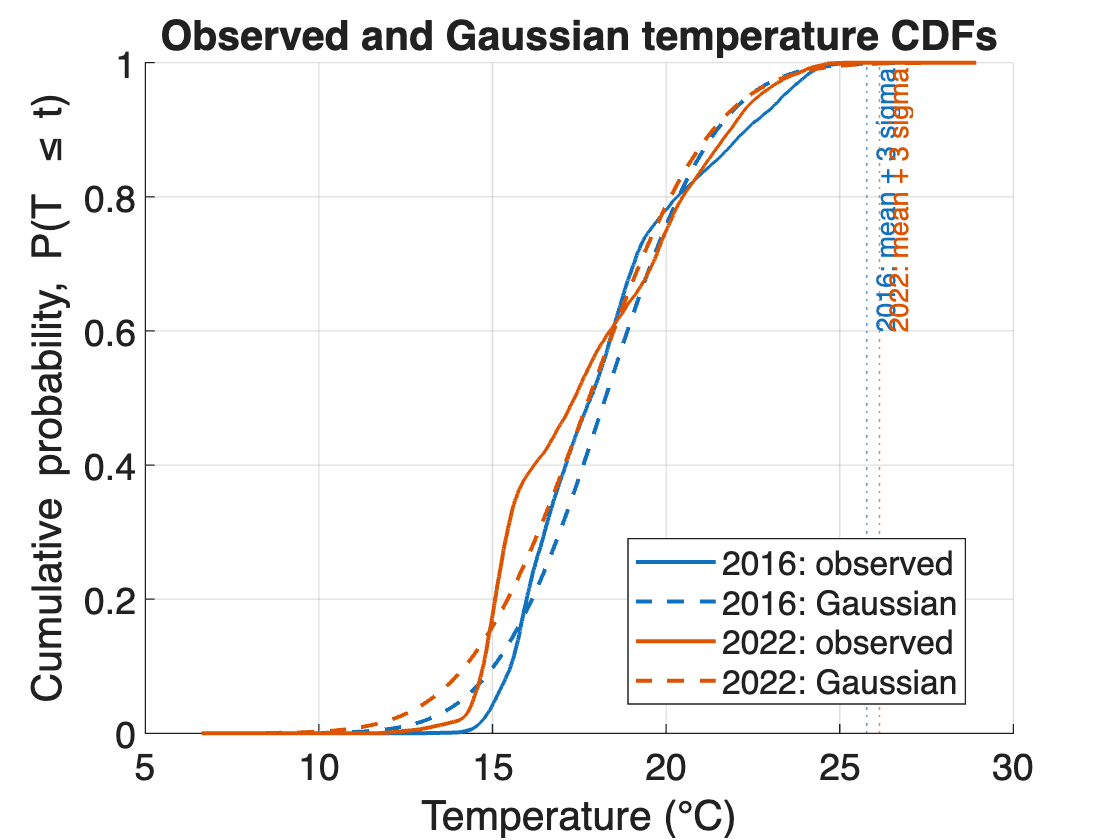


2016 temperature extremes
Mean: 18.25 °C
Standard deviation: 2.51 °C
Threshold (mean + 3 sigma): 25.78 °C
Observed exceedances: 0 of 94466
Observed probability: 0 (0%)
Gaussian probability: 0.0013499 (0.135%)

2022 temperature extremes
Mean: 17.78 °C
Standard deviation: 2.788 °C
Threshold (mean + 3 sigma): 26.15 °C
Observed exceedances: 0 of 126517
Observed probability: 0 (0%)
Gaussian probability: 0.0013499 (0.135%)


In [37]:
years = [2016, 2022];
colors = lines(2);

figure;
hold on;

for j = 1:numel(years)
    data = pierbyyr.(sprintf('yr_%d', years(j)));

    x = data.t(:);

    mu = mean(x);
    sigma = std(x);
    n = numel(x);

    threshold = mu + 3*sigma;

    pObserved = sum(x > threshold)/n;

    pGaussian = 0.5*erfc((threshold-mu)/(sigma*sqrt(2)));

    [xUnique, ~, group] = unique(x);
    counts = accumarray(group, 1);
    FObserved = cumsum(counts)/n;

    xmin = min(min(x), mu - 4*sigma);
    xmax = max(max(x), mu + 4*sigma);
    xgrid = linspace(xmin, xmax, 1000);
    FGaussian = 0.5*erfc(-(xgrid-mu)/(sigma*sqrt(2)));

    % Plot CDFs
    stairs([xmin; xUnique; xmax], [0; FObserved; 1], ...
        'Color', colors(j,:), 'LineWidth', 1.5, ...
        'DisplayName', sprintf('%d: observed', years(j)));

    plot(xgrid, FGaussian, '--', ...
        'Color', colors(j,:), 'LineWidth', 1.5, ...
        'DisplayName', sprintf('%d: Gaussian', years(j)));

    xline(threshold, ':', sprintf('%d: mean + 3 sigma', years(j)), ...
        'Color', colors(j,:), 'HandleVisibility', 'off');

    fprintf('\n%d temperature extremes\n', years(j));
    fprintf('Mean: %.4g °C\n', mu);
    fprintf('Standard deviation: %.4g °C\n', sigma);
    fprintf('Threshold (mean + 3 sigma): %.4g °C\n', threshold);
    fprintf('Observed exceedances: %d of %d\n', sum(x > threshold), n);
    fprintf('Observed probability: %.5g (%.4g%%)\n', ...
        pObserved, 100*pObserved);
    fprintf('Gaussian probability: %.5g (%.4g%%)\n', ...
        pGaussian, 100*pGaussian);
end

xlabel('Temperature (°C)');
ylabel('Cumulative probability, P(T \leq t)');
title('Observed and Gaussian temperature CDFs');
ylim([0 1]);
legend('Location', 'best');
grid on;
hold off;

In [36]:
%% 6: Variance reduction by averaging.
% As a bonus, can you demonstrate that the
% sample variance of N -sample averages decreases as N as we learned in class?

% I attempted this but as I am already brain tired and late... I decided against pursuing it further. 